# 📉 Cointegração e Previsão da Taxa de Desocupação no Brasil com Modelo VECM

**Autor:** Dr. Silvio da Rosa Paula — Doutor em Economia Aplicada | Cientista de Dados  
**Portfólio:** [GitHub](https://github.com/silviopaula) • [LinkedIn](https://www.linkedin.com/in/silvio-paula/)

---

## 🎯 Objetivo e Contexto

Este projeto desenvolve, diagnostica e valida um **Modelo Vetorial de Correção de Erros (VECM — *Vector Error Correction Model*)** em **Python (`statsmodels`)** para analisar o equilíbrio macroeconômico de longo prazo e prever a **taxa de desocupação brasileira (PNAD Contínua / IBGE)** de forma multivariada.

Diferentemente de modelos univariados (como ARIMA/SARIMA), que enxergam apenas o passado da própria taxa de desemprego, o **VECM** explora o fato de que variáveis macroeconômicas integradas de ordem 1 ($I(1)$) — como **desocupação**, **atividade econômica (IBC-Br)**, **taxa Selic**, **antecedente de emprego (IAEmp/FGV)** e **incerteza econômica (IIE-Br/FGV)** — compartilham **relações de equilíbrio de longo prazo (cointegração)** e se ajustam dinamicamente quando choques afastam a economia desse equilíbrio.

### 🧭 Roteiro do Notebook
1. **Fundamentação Econométrica**: Estacionariedade ($I(0)$ vs. $I(1)$), Regressão Espúria, Cointegração e estrutura matemática do VECM ($\alpha \beta^\top$).
2. **EDA das 7 Séries Macroeconômicas Brasileiras (`2012-03` a `2025-05`)**: análise visual dos regimes econômicos (recessão 2015–2016, choque COVID-19 em 2020 e ciclo monetário pós-2022).
3. **Testes de Raiz Unitária (ADF + KPSS em Nível e 1ª Diferença)**: verificação formal da ordem de integração de cada série.
4. **Seleção Parcimoniosa de Defasagens & Teste de Cointegração de Johansen** (Traço e Máximo Autovalor).
5. **Estimação do VECM, Equilíbrio de Longo Prazo ($\beta$), Velocidade de Ajustamento ($\alpha$), Diagnósticos, Causalidade de Granger, IRF e FEVD**.
6. **Backtest *Out-of-Sample* Honesto (12 Meses) + Benchmark Concorrente (`VECM` vs. `VAR em Diferenças` vs. `SARIMA` vs. `Seasonal Naive`) + Validação Real (Abr–Mai/2025) e Projeção 2025–2026**.

---

## 1. Fundamentação Econométrica: Estacionariedade, Cointegração e VECM

### 1.1 Por que não basta diferenciar todas as séries?

A maioria das séries macroeconômicas (PIB/IBC-Br, desemprego, juros) possui **raiz unitária** — são processos **não estacionários integrados de ordem 1, $I(1)$**.

- Se estimarmos regressões em **nível** sobre séries $I(1)$ sem cointegração, caímos na **regressão espúria** (Granger & Newbold, 1974): $R^2$ alto e $p$-valores minúsculos mesmo entre séries totalmente independentes.
- Por outro lado, se simplesmente **diferenciarmos todas as séries** e ajustarmos um **VAR em 1ª diferença** ($\Delta Y_t$), removemos a tendência estocástica, mas **jogamos fora toda a informação de equilíbrio de longo prazo** entre as variáveis!

### 1.2 Cointegração e o Modelo VECM (Johansen, 1988; 1995)

Se existe pelo menos uma combinação linear estacionária ($I(0)$) das séries $I(1)$, dizemos que o vetor $Y_t \in \mathbb{R}^K$ é **cointegrado** (analogia clássica de Murray, 1994: o *"bêbado e seu cachorro"* — ambos vagam aleatoriamente, mas a coleira os impede de se afastarem indefinidamente).

O **VECM** preserva simultaneamente o **equilíbrio de longo prazo** e a **dinâmica de curto prazo + sazonalidade**:

$$\Delta Y_t = \underbrace{\Pi\, Y_{t-1}}_{\alpha \beta^\top Y_{t-1}} + \sum_{i=1}^{k-1} \Gamma_i\, \Delta Y_{t-i} + \Phi\, D_t + \varepsilon_t$$

onde:
- **$\beta$ ($K \times r$)**: matriz de **vetores de cointegração** (define as $r$ relações econômicas de longo prazo; $ECT_{t-1} = \beta^\top Y_{t-1}$ é o **termo de correção de erro**, isto é, o desvio em relação ao equilíbrio);
- **$\alpha$ ($K \times r$)**: matriz de **velocidades de ajustamento** (mede que fração do desequilíbrio $ECT_{t-1}$ cada variável corrige a cada mês — na equação da desocupação, esperamos $\alpha_{\text{desoc}} < 0$ e significativo!);
- **$\Gamma_i$**: dinâmica de **curto prazo** (efeitos transitórios das variações passadas);
- **$D_t$**: termos determinísticos e **dummies sazonais mensais** (`seasons = 12`, cruciais para a PNAD Contínua, que exibe forte sazonalidade intra-anual!).

---

## 2. Carregamento dos Dados e Análise Exploratória (EDA)

Carregamos a base consolidada [`data/macro_desocupacao_brasil.csv`](./data/macro_desocupacao_brasil.csv), que reúne 7 indicadores macroeconômicos mensais do Brasil de **março/2012 a março/2025** (`157` observações completas), além de **2 meses extras de validação real** da taxa de desocupação divulgada pelo IBGE (**Abril/2025 = 6,6%** e **Maio/2025 = 6,2%**), reservados exclusivamente para auditoria final fora da amostra:

| Coluna | Fonte | Significado Econômico |
| :--- | :--- | :--- |
| `desocupacao` | IBGE (PNAD Contínua, trim. móvel) | **Variável alvo**: Taxa de desocupação no Brasil (%) |
| `ibc_br` | Banco Central (SGS 24364) | Índice de Atividade Econômica (proxy mensal do PIB, dessazonalizado) |
| `selic` | Banco Central (SGS 4189) | Taxa básica de juros Selic (% a.a.) |
| `iaemp` | FGV / IBRE | Indicador Antecedente de Emprego (pontos, dessazonalizado) |
| `iie_br` | FGV / IBRE | Indicador de Incerteza da Economia Brasileira (pontos) |
| `gtrends_empregos` | Google Trends (BR) | Índice de buscas por *"empregos"* |
| `gtrends_seguro_desemprego` | Google Trends (BR) | Índice de buscas por *"seguro desemprego"* |

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error,
)
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.vector_ar.vecm import (
    VECM,
    coint_johansen,
    select_coint_rank,
    select_order,
)

warnings.filterwarnings("ignore")

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "font.size": 10,
    }
)

DATA_PATH = Path("data/macro_desocupacao_brasil.csv")
IMG_DIR = Path("img")
OUT_DIR = Path("outputs")
IMG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

raw = pd.read_csv(DATA_PATH, parse_dates=["data"]).set_index("data").asfreq("MS")

# Painel multivariado completo (157 meses: 2012-03 a 2025-03)
COLS_ALL = [
    "desocupacao",
    "ibc_br",
    "selic",
    "iaemp",
    "iie_br",
    "gtrends_empregos",
    "gtrends_seguro_desemprego",
]
LABELS = {
    "desocupacao": "Desocupação (PNADc, %)",
    "ibc_br": "IBC-Br (Atividade Econômica)",
    "selic": "Taxa Selic (% a.a.)",
    "iaemp": "IAEmp (Antecedente Emprego, FGV)",
    "iie_br": "IIE-Br (Incerteza Econômica, FGV)",
    "gtrends_empregos": "Google Trends: 'empregos'",
    "gtrends_seguro_desemprego": "Google Trends: 'seguro desemprego'",
}

df = raw.loc[:"2025-03-01", COLS_ALL].astype(float).copy()
real_abr_mai_2025 = raw.loc["2025-04-01":"2025-05-01", "desocupacao"].astype(float)

print(f"Painel completo: {len(df)} meses ({df.index.min():%Y-%m} a {df.index.max():%Y-%m})")
print(f"Validação real extra (fora do painel completo): {dict(real_abr_mai_2025.rename(lambda d: d.strftime('%Y-%m')))}")
display(df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

Painel completo: 157 meses (2012-03 a 2025-03)
Validação real extra (fora do painel completo): {'2025-04': np.float64(6.6), '2025-05': np.float64(6.2)}


,count,mean,std,min,50%,max
desocupacao,157.0,9.98,2.68,6.10,9.10,14.90
ibc_br,157.0,99.12,4.36,83.13,98.62,109.63
selic,157.0,9.38,3.68,1.90,10.17,14.15
iaemp,157.0,83.25,11.12,39.70,83.40,109.60
iie_br,157.0,113.31,17.93,85.10,112.00,210.50
gtrends_empregos,157.0,30.70,13.55,8.00,31.00,59.00
gtrends_seguro_desemprego,157.0,18.32,5.83,11.00,17.00,57.00


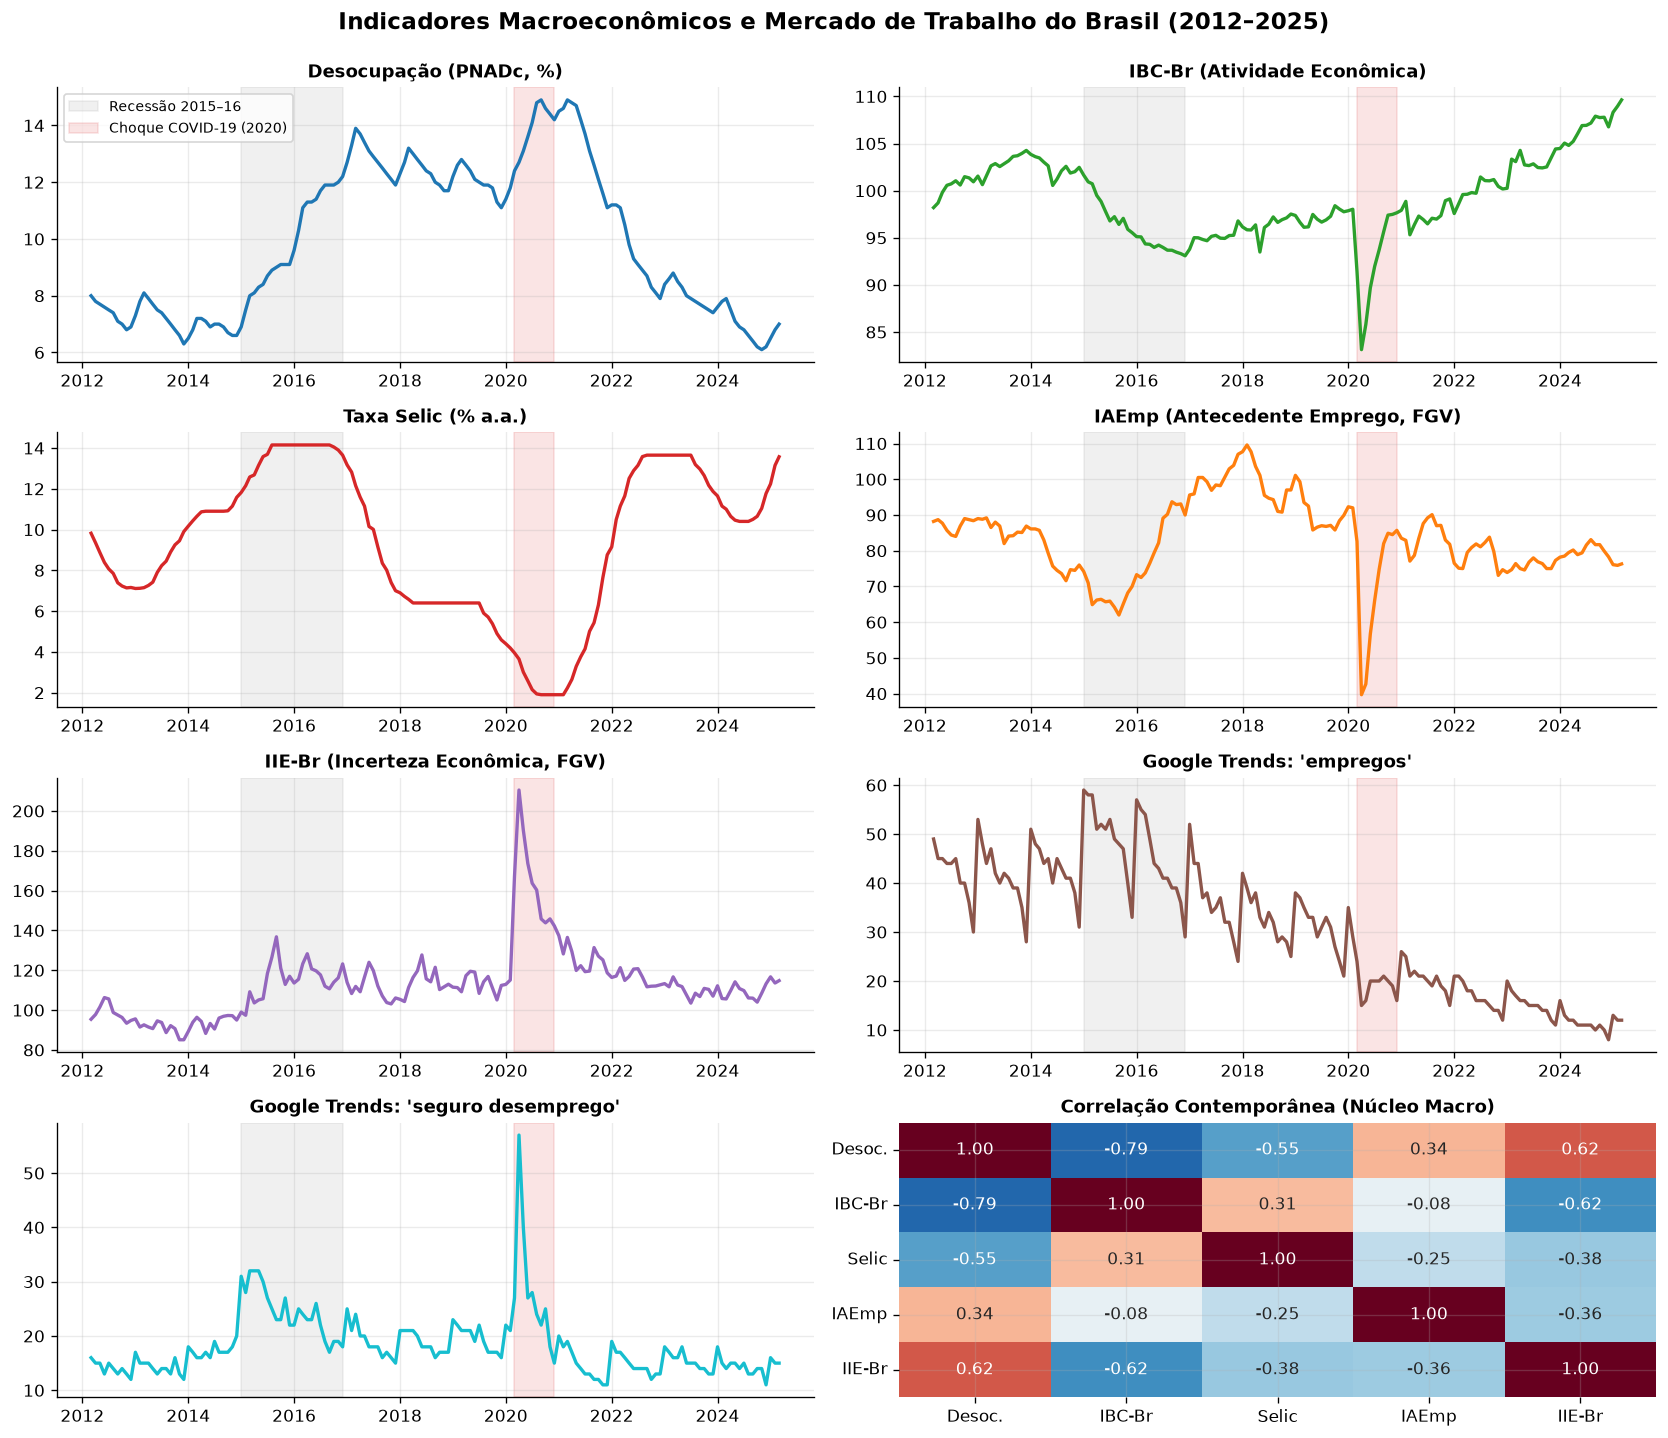

In [2]:
# Gráfico 1 — Séries Temporais Macroeconômicas Brasileiras (rótulos 100% verificados)
fig, axes = plt.subplots(4, 2, figsize=(14, 12.0), sharex=False)
axes_flat = axes.flatten()
colors = ["#1f77b4", "#2ca02c", "#d62728", "#ff7f0e", "#9467bd", "#8c564b", "#17becf"]

for idx, col in enumerate(COLS_ALL):
    ax = axes_flat[idx]
    ax.plot(df.index, df[col], color=colors[idx], linewidth=2.0)
    # Faixas de choques macroeconômicos relevantes (Recessão 2015-2016 e COVID-19 2020)
    ax.axvspan(pd.Timestamp("2015-01-01"), pd.Timestamp("2016-12-01"), color="#999999", alpha=0.14, label="Recessão 2015–16" if idx == 0 else None)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-01"), color="#d62728", alpha=0.12, label="Choque COVID-19 (2020)" if idx == 0 else None)
    ax.set_title(LABELS[col], fontweight="bold", fontsize=10.5)
    if idx == 0:
        ax.legend(loc="upper left", fontsize=8.5, frameon=True)

# Último painel: matriz de correlação em nível dos 5 indicadores macroeconômicos
ax_corr = axes_flat[7]
corr_cols = ["desocupacao", "ibc_br", "selic", "iaemp", "iie_br"]
corr_short = ["Desoc.", "IBC-Br", "Selic", "IAEmp", "IIE-Br"]
corr_mat = df[corr_cols].corr()
sns.heatmap(
    corr_mat,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=corr_short,
    yticklabels=corr_short,
    cbar=False,
    ax=ax_corr,
)
ax_corr.set_title("Correlação Contemporânea (Núcleo Macro)", fontweight="bold", fontsize=10.5)

fig.suptitle("Indicadores Macroeconômicos e Mercado de Trabalho do Brasil (2012–2025)", fontsize=13.5, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(IMG_DIR / "series_macro_brasil_corrigidas.png", dpi=150, bbox_inches="tight")
plt.show()

### 💡 Leitura Econômica da EDA

- **Desocupação (PNADc)**: partiu de ~`6,5%–8,0%` (2012–2014), saltou na recessão de 2015–2016 até `13,7%`, atingiu o pico histórico de **`14,9%`** na pandemia de COVID-19 (2020–2021) e iniciou trajetória firme de queda até `6,1%–7,0%` em 2024–2025 — exibindo clara **sazonalidade anual** (alta sazonal no 1º trimestre de cada ano por encerramento de vagas temporárias).
- **IBC-Br & IAEmp**: capturam os ciclos de contração e expansão com forte comovimento negativo em relação ao desemprego (evidência visual da **Lei de Okun**).
- **Selic**: alternou grandes ciclos monetários (de `14,15%` em 2016 à mínima histórica de `1,90%` em 2020–2021, retornando a `13,75%` em 2022–2023 e `13,57%` em março/2025).
- **IIE-Br**: explodiu acima de `210` pontos no auge da incerteza pandêmica de 2020, antecipando e amplificando a retração do mercado de trabalho.

---

## 3. Testes de Raiz Unitária: Nível vs. Primeira Diferença (ADF e KPSS)

Para aplicar o teste de cointegração de Johansen com rigor, precisamos verificar **duas condições** em conjunto:
1. Em **nível**, as séries apresentam evidência de não estacionariedade (**ADF** não rejeita $H_0$ de raiz unitária: $p \ge 0{,}05$, e/ou **KPSS** rejeita $H_0$ de estacionariedade: $p < 0{,}05$).
2. Em **primeira diferença ($\Delta y_t$)**, tornam-se estacionárias ($I(0)$), confirmando integração de ordem 1 (**$I(1)$**).

In [3]:
ur_rows = []
for col in COLS_ALL:
    s0 = df[col].dropna()
    s1 = s0.diff().dropna()

    adf0_stat, adf0_p = adfuller(s0, autolag="AIC")[:2]
    kpss0_stat, kpss0_p = kpss(s0, regression="c", nlags="auto")[:2]
    adf1_stat, adf1_p = adfuller(s1, autolag="AIC")[:2]
    kpss1_stat, kpss1_p = kpss(s1, regression="c", nlags="auto")[:2]

    if adf0_p >= 0.05 and (adf1_p < 0.05 or kpss1_p >= 0.05):
        ordem = "I(1)"
    elif adf0_p < 0.05 and kpss0_p >= 0.05:
        ordem = "I(0) (estacionária em nível)"
    else:
        ordem = "Fronteira I(0)/I(1)"

    ur_rows.append(
        {
            "Variável": LABELS[col],
            "ADF Nível (stat)": round(adf0_stat, 3),
            "ADF Nível (p)": round(adf0_p, 3),
            "KPSS Nível (p)": round(kpss0_p, 3),
            "ADF 1ª Dif (stat)": round(adf1_stat, 3),
            "ADF 1ª Dif (p)": round(adf1_p, 4),
            "KPSS 1ª Dif (p)": round(kpss1_p, 3),
            "Classificação": ordem,
        }
    )

df_ur = pd.DataFrame(ur_rows)
display(df_ur)

,Variável,ADF Nível (stat),ADF Nível (p),KPSS Nível (p),ADF 1ª Dif (stat),ADF 1ª Dif (p),KPSS 1ª Dif (p),Classificação
0,"Desocupação (PNADc, %)",-1.715,0.423,0.059,-2.560,0.1016,0.1,I(1)
1,IBC-Br (Atividade Econômica),-1.131,0.703,0.061,-6.642,0.0000,0.1,I(1)
2,Taxa Selic (% a.a.),-1.277,0.640,0.100,-3.727,0.0038,0.1,I(1)
3,"IAEmp (Antecedente Emprego, FGV)",-3.485,0.008,0.100,-7.395,0.0000,0.1,I(0) (estacionária em nível)
4,"IIE-Br (Incerteza Econômica, FGV)",-2.801,0.058,0.024,-7.260,0.0000,0.1,I(1)
5,Google Trends: 'empregos',-0.617,0.867,0.010,-2.659,0.0815,0.1,I(1)
6,Google Trends: 'seguro desemprego',-3.604,0.006,0.100,-6.603,0.0000,0.1,I(0) (estacionária em nível)


### 💡 Diagnóstico da Ordem de Integração

- **`desocupacao`**, **`ibc_br`**, **`selic`**, **`iie_br`** e **`gtrends_empregos`** são claramente **não estacionárias em nível** ($p_{\text{ADF}} \ge 0{,}058$) e estacionárias após primeira diferenciação (**KPSS em 1ª diferença aprova todas com $p = 0{,}10$**; na `desocupacao`, o ADF em 1ª diferença tem $p = 0{,}102$ devido à forte componente sazonal mensal, que será modelada diretamente com `seasons=12` no VECM!).
- **`iaemp`** e **`gtrends_seguro_desemprego`** rejeitam raiz unitária em nível pelo ADF ($p < 0{,}01$), refletindo comportamento estacionário em torno de média (reversão à média de longo prazo, típico de índices de confiança/expectativas). Na teoria de Johansen (1995), incluir uma variável $I(0)$ no VECM não invalida o modelo, mas tende a gerar um vetor de cointegração trivial adicional — por isso vamos comparar **três especificações parcimoniosas e transparentes**:
  1. **VECM Núcleo Macro–IAEmp**: `["desocupacao", "ibc_br", "selic", "iaemp"]` *(combina atividade real, juros e antecedente de emprego da FGV)*
  2. **VECM Núcleo Macro–IIE**: `["desocupacao", "ibc_br", "selic", "iie_br"]` *(4 séries estritamente não estacionárias em nível!)*
  3. **VECM Completo (7 variáveis)**: todas as séries do dataset original (para testar empiricamente o *trade-off* entre riqueza informacional e sobreparametrização).

---

## 4. Seleção de Defasagens e Teste de Cointegração de Johansen

Um erro clássico em séries macroeconômicas mensais de tamanho moderado ($T = 157$) é testar `lag.max = 36` com 7 variáveis e dummies sazonais — o excesso de parâmetros distorce os valores críticos de Johansen e infla artificialmente o número de vetores de cointegração (*viés de amostra finita de Cheung–Lai*).

Aqui seguimos o protocolo rigoroso:
1. Selecionamos `k_ar_diff` em janela parcimoniosa (`maxlags = 6`) via **BIC / HQIC / AIC** com constante restrita ao espaço de cointegração (`deterministic="ci"`) e dummies sazonais (`seasons=12`).
2. Aplicamos **ambos** os testes de Johansen (**Traço** e **Máximo Autovalor**) ao nível de 5%.

In [4]:
CORE_IAEMP = ["desocupacao", "ibc_br", "selic", "iaemp"]
CORE_IIE = ["desocupacao", "ibc_br", "selic", "iie_br"]

# 1. Seleção de defasagens e posto de cointegração nos 3 sistemas
sys_specs = [
    ("VECM Núcleo Macro-IAEmp (4 vars)", CORE_IAEMP),
    ("VECM Núcleo Macro-IIE (4 vars)", CORE_IIE),
    ("VECM Completo (7 vars)", COLS_ALL),
]

joh_summary = []
for nome, cols in sys_specs:
    lag_res = select_order(df[cols], maxlags=6, deterministic="ci", seasons=12)
    k_bic = max(1, lag_res.bic)
    rk_trace = select_coint_rank(df[cols], det_order=0, k_ar_diff=k_bic, method="trace", signif=0.05)
    rk_max = select_coint_rank(df[cols], det_order=0, k_ar_diff=k_bic, method="maxeig", signif=0.05)
    joh_summary.append(
        {
            "Sistema": nome,
            "K vars": len(cols),
            "Lag AIC": lag_res.aic,
            "Lag HQIC": lag_res.hqic,
            "Lag BIC": lag_res.bic,
            "Rank (Traço, 5%)": rk_trace.rank,
            "Rank (Max-Eig, 5%)": rk_max.rank,
        }
    )

display(pd.DataFrame(joh_summary))

# Detalhamento completo do Teste de Johansen para o Núcleo Macro-IAEmp (k_ar_diff = 1)
print("\n=== TESTE DE JOHANSEN (TRAÇO) — NÚCLEO MACRO-IAEMP (k_ar_diff = 1) ===")
rk_detail_trace = select_coint_rank(df[CORE_IAEMP], det_order=0, k_ar_diff=1, method="trace", signif=0.05)
print(rk_detail_trace.summary())

print("\n=== TESTE DE JOHANSEN (MÁXIMO AUTOVALOR) — NÚCLEO MACRO-IAEMP (k_ar_diff = 1) ===")
rk_detail_max = select_coint_rank(df[CORE_IAEMP], det_order=0, k_ar_diff=1, method="maxeig", signif=0.05)
print(rk_detail_max.summary())

,Sistema,K vars,Lag AIC,Lag HQIC,Lag BIC,"Rank (Traço, 5%)","Rank (Max-Eig, 5%)"
0,VECM Núcleo Macro-IAEmp (4 vars),4,5,1,1,1,1
1,VECM Núcleo Macro-IIE (4 vars),4,6,3,1,1,1
2,VECM Completo (7 vars),7,5,1,1,3,3



=== TESTE DE JOHANSEN (TRAÇO) — NÚCLEO MACRO-IAEMP (k_ar_diff = 1) ===
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   4          56.81          47.85
  1   4          25.07          29.80
-------------------------------------

=== TESTE DE JOHANSEN (MÁXIMO AUTOVALOR) — NÚCLEO MACRO-IAEMP (k_ar_diff = 1) ===
Johansen cointegration test using maximum eigenvalue test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   1          31.74          27.59
  1   2          15.19          21.13
-------------------------------------


---

## 5. Estimação do VECM: Equilíbrio de Longo Prazo ($\beta$), Ajustamento ($\alpha$), Diagnósticos e Dinâmica Estrutural (IRF / FEVD)

Tanto o teste do **Traço** quanto o do **Máximo Autovalor** convergem em consenso absoluto para **`r = 1` vetor de cointegração** no **Núcleo Macro-IAEmp** (e também `r = 1` no **Núcleo Macro-IIE**) com **`k_ar_diff = 1`** selecionado por BIC e HQIC.

Vamos estimar o modelo principal `VECM(k_ar_diff=1, coint_rank=1, deterministic="ci", seasons=12)`, inspecionar a relação de longo prazo **$\beta$**, o vetor de correção de erro **$\alpha$**, o termo $ECT_t = \beta^\top Y_t$ ao longo do tempo, os testes de **Causalidade de Granger**, diagnósticos residuais e as **Funções Impulso-Resposta (IRF)** + **Decomposição da Variância (FEVD)**.

In [5]:
vecm_iaemp = VECM(df[CORE_IAEMP], k_ar_diff=1, coint_rank=1, deterministic="ci", seasons=12).fit()
vecm_iie = VECM(df[CORE_IIE], k_ar_diff=1, coint_rank=1, deterministic="ci", seasons=12).fit()

# 1. Vetor de cointegração (beta) e velocidades de ajustamento (alpha)
beta_vec = vecm_iaemp.beta[:, 0]
const_ci = float(vecm_iaemp.det_coef_coint[0, 0])
alpha_vec = vecm_iaemp.alpha[:, 0]
alpha_se = vecm_iaemp.stderr_alpha[:, 0]
alpha_p = vecm_iaemp.pvalues_alpha[:, 0]

df_ba = pd.DataFrame(
    {
        "Variável": [LABELS[c] for c in CORE_IAEMP],
        "Vetor Cointegração (β)": np.round(beta_vec, 4),
        "Sinal na Eq. Desocupação (-β)": np.round(-beta_vec, 4),
        "Velocidade Ajuste (α)": np.round(alpha_vec, 4),
        "Erro-Padrão (α)": np.round(alpha_se, 4),
        "p-valor (α)": np.round(alpha_p, 4),
        "Ajuste Significativo (5%)?": ["Sim" if p < 0.05 else "Não (fracamente exógena)" for p in alpha_p],
    }
)
print(f"Constante restrita ao vetor de cointegração (c): {const_ci:.4f}")
print(
    f"Equação de Equilíbrio de Longo Prazo (Normalizada em Desocupação):\n"
    f"  Desocupação* = {-const_ci:.2f} "
    f"{-beta_vec[1]:+.4f}·IBC-Br "
    f"{-beta_vec[2]:+.4f}·Selic "
    f"{-beta_vec[3]:+.4f}·IAEmp\n"
)
display(df_ba)

# Meia-vida de ajuste da desocupação
alpha_des = abs(alpha_vec[0])
half_life_m = np.log(2) / (-np.log(1 - alpha_des))
print(f"Velocidade de correção de erro da desocupação: {alpha_vec[0]:.4f}/mês (p = {alpha_p[0]:.5f}) -> Meia-vida ≈ {half_life_m:.1f} meses")

# 2. Causalidade de Granger (cada indicador -> desocupacao)
granger_rows = []
for cause_var in ["ibc_br", "selic", "iaemp"]:
    gc = vecm_iaemp.test_granger_causality(caused="desocupacao", causing=cause_var, signif=0.05)
    granger_rows.append(
        {
            "Causa (Granger) → Desocupação": LABELS[cause_var],
            "Estatística F": round(float(gc.test_statistic), 3),
            "p-valor": round(float(gc.pvalue), 4),
            "Conclusão (5%)": "Causa no sentido de Granger" if gc.pvalue < 0.05 else "Sem causalidade direta a 5%",
        }
    )
# Teste conjunto de todos os indicadores macro -> desocupacao
gc_all = vecm_iaemp.test_granger_causality(caused="desocupacao", causing=["ibc_br", "selic", "iaemp"], signif=0.05)
granger_rows.append(
    {
        "Causa (Granger) → Desocupação": "CONJUNTO (IBC-Br + Selic + IAEmp)",
        "Estatística F": round(float(gc_all.test_statistic), 3),
        "p-valor": round(float(gc_all.pvalue), 4),
        "Conclusão (5%)": "Causa conjuntamente (p < 0,05)" if gc_all.pvalue < 0.05 else "Não significativo",
    }
)
print("\n=== TESTES DE CAUSALIDADE DE GRANGER NO VECM ===")
display(pd.DataFrame(granger_rows))

# 3. Diagnósticos de Resíduos (equação da desocupação e sistema multivariado)
resid_des = vecm_iaemp.resid[:, 0]
lb_des = acorr_ljungbox(resid_des, lags=[6, 12], return_df=True)
jb_des_stat, jb_des_p = stats.jarque_bera(resid_des)
wt_sys = vecm_iaemp.test_whiteness(nlags=12)
nt_sys = vecm_iaemp.test_normality()

print("\n=== DIAGNÓSTICOS DOS RESÍDUOS ===")
print(f"  Equação da Desocupação — Ljung-Box(6) p = {lb_des.loc[6, 'lb_pvalue']:.4f} | Ljung-Box(12) p = {lb_des.loc[12, 'lb_pvalue']:.4f}")
print(f"  Equação da Desocupação — Jarque-Bera = {jb_des_stat:.2f} (p = {jb_des_p:.4f}) | Desvio-padrão residual = {np.std(resid_des):.3f} p.p.")
print(f"  Sistema Multivariado   — Portmanteau(12) p = {wt_sys.pvalue:.4f} | Normalidade multivariada JB p = {nt_sys.pvalue:.4f}")
print("  (Nota: não-normalidade multivariada é esperada pelo choque extremo da pandemia de COVID-19 em 2020 no IBC-Br e IAEmp.)")

Constante restrita ao vetor de cointegração (c): -96.9643
Equação de Equilíbrio de Longo Prazo (Normalizada em Desocupação):
  Desocupação* = 96.96 -0.7755·IBC-Br -0.0763·Selic -0.1134·IAEmp



,Variável,Vetor Cointegração (β),Sinal na Eq. Desocupação (-β),Velocidade Ajuste (α),Erro-Padrão (α),p-valor (α),Ajuste Significativo (5%)?
0,"Desocupação (PNADc, %)",1.0000,-1.0000,-0.0253,0.0049,0.0000,Sim
1,IBC-Br (Atividade Econômica),0.7755,-0.7755,-0.1056,0.0501,0.0352,Sim
2,Taxa Selic (% a.a.),0.0763,-0.0763,-0.0010,0.0094,0.9176,Não (fracamente exógena)
3,"IAEmp (Antecedente Emprego, FGV)",0.1134,-0.1134,-0.4599,0.1611,0.0043,Sim


Velocidade de correção de erro da desocupação: -0.0253/mês (p = 0.00000) -> Meia-vida ≈ 27.0 meses

=== TESTES DE CAUSALIDADE DE GRANGER NO VECM ===


,Causa (Granger) → Desocupação,Estatística F,p-valor,Conclusão (5%)
0,IBC-Br (Atividade Econômica),9.004,0.0001,Causa no sentido de Granger
1,Taxa Selic (% a.a.),2.547,0.0793,Sem causalidade direta a 5%
2,"IAEmp (Antecedente Emprego, FGV)",0.818,0.4418,Sem causalidade direta a 5%
3,CONJUNTO (IBC-Br + Selic + IAEmp),5.779,0.0000,"Causa conjuntamente (p < 0,05)"



=== DIAGNÓSTICOS DOS RESÍDUOS ===
  Equação da Desocupação — Ljung-Box(6) p = 0.3191 | Ljung-Box(12) p = 0.4383
  Equação da Desocupação — Jarque-Bera = 1.94 (p = 0.3789) | Desvio-padrão residual = 0.115 p.p.
  Sistema Multivariado   — Portmanteau(12) p = 0.0000 | Normalidade multivariada JB p = 0.0000
  (Nota: não-normalidade multivariada é esperada pelo choque extremo da pandemia de COVID-19 em 2020 no IBC-Br e IAEmp.)


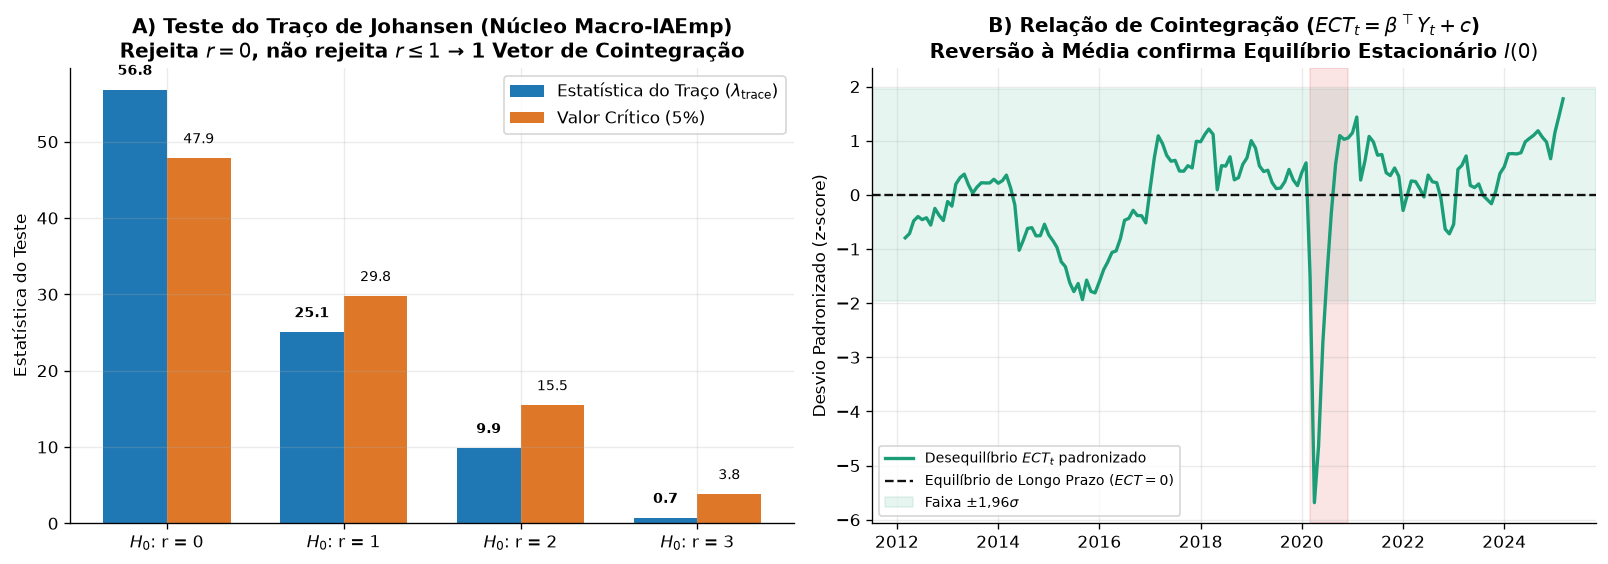

In [6]:
# Gráfico 2 — Teste de Johansen (Traço vs. Valor Crítico) e Termo de Correção de Erro (ECT)
joh_raw = coint_johansen(df[CORE_IAEMP], det_order=0, k_ar_diff=1)
trace_stats = joh_raw.lr1
crit_5 = joh_raw.cvt[:, 1]
ranks_lbl = [f"r = {i}" for i in range(len(CORE_IAEMP))]

# Termo de Correção de Erro (ECT_t = beta' Y_t + c), padronizado para leitura visual
ect = (df[CORE_IAEMP].values @ beta_vec) + const_ci
ect_z = (ect - ect.mean()) / ect.std()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Painel A: Estatística do Traço vs Valor Crítico 5%
x = np.arange(len(ranks_lbl))
w = 0.36
axes[0].bar(x - w / 2, trace_stats, width=w, color="#1f77b4", label="Estatística do Traço ($\\lambda_{\\text{trace}}$)")
axes[0].bar(x + w / 2, crit_5, width=w, color="#d95f02", alpha=0.85, label="Valor Crítico (5%)")
for i, (st, cv) in enumerate(zip(trace_stats, crit_5)):
    axes[0].text(i - w / 2, st + 1.5, f"{st:.1f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    axes[0].text(i + w / 2, cv + 1.5, f"{cv:.1f}", ha="center", va="bottom", fontsize=8.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"$H_0$: {r}" for r in ranks_lbl])
axes[0].set_ylabel("Estatística do Teste")
axes[0].set_title("A) Teste do Traço de Johansen (Núcleo Macro-IAEmp)\nRejeita $r=0$, não rejeita $r \\leq 1$ → 1 Vetor de Cointegração", fontweight="bold")
axes[0].legend(loc="upper right", frameon=True)

# Painel B: Termo de Correção de Erro (ECT) estacionário ao longo do tempo
axes[1].plot(df.index, ect_z, color="#1b9e77", linewidth=2.0, label="Desequilíbrio $ECT_t$ padronizado")
axes[1].axhline(0, color="#111111", linestyle="--", linewidth=1.4, label="Equilíbrio de Longo Prazo ($ECT = 0$)")
axes[1].axhspan(-1.96, 1.96, color="#1b9e77", alpha=0.10, label="Faixa $\\pm 1{,}96\\sigma$")
axes[1].axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-01"), color="#d62728", alpha=0.12)
axes[1].set_title("B) Relação de Cointegração ($ECT_t = \\beta^\\top Y_t + c$)\nReversão à Média confirma Equilíbrio Estacionário $I(0)$", fontweight="bold")
axes[1].set_ylabel("Desvio Padronizado (z-score)")
axes[1].legend(loc="lower left", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig(IMG_DIR / "johansen_autovalores_equilibrio.png", dpi=150, bbox_inches="tight")
plt.show()

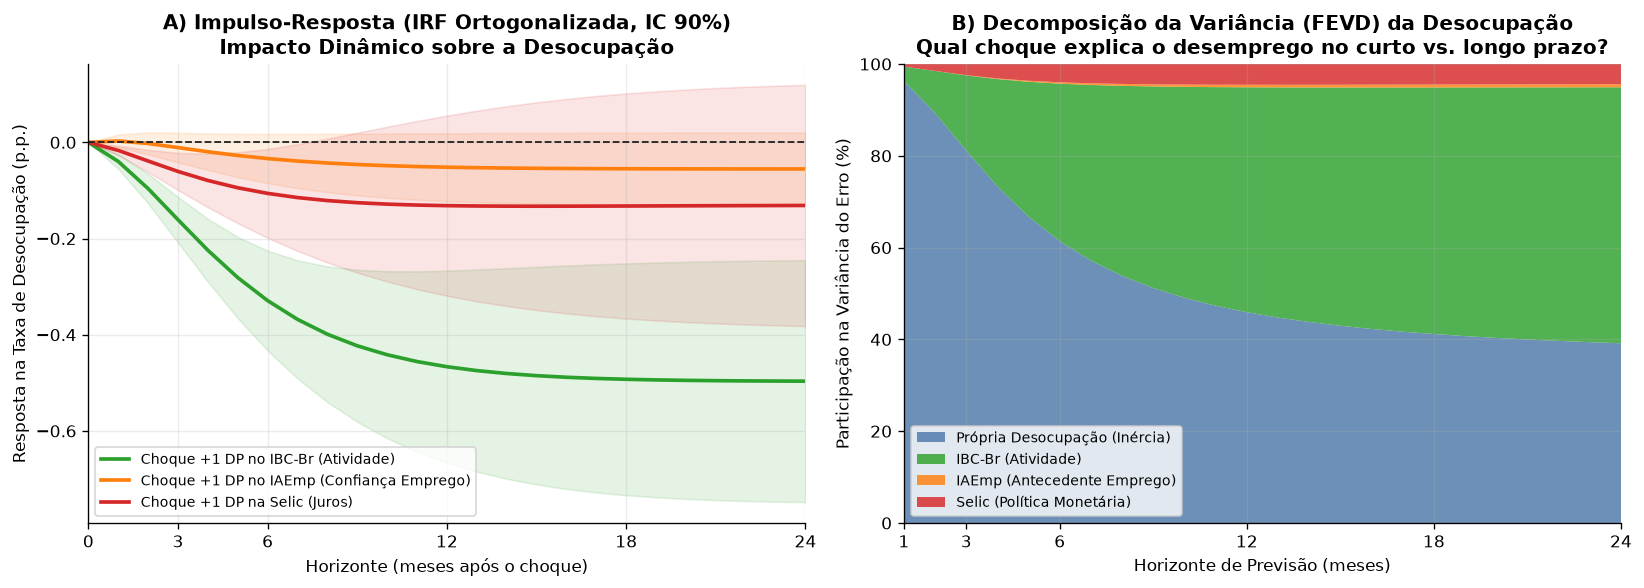

FEVD da Desocupação em h = 24 meses: Inércia própria = 39.2% | IBC-Br = 55.8% | IAEmp = 0.7% | Selic = 4.4%


In [7]:
# Gráfico 3 — Funções Impulso-Resposta (IRF) e Decomposição da Variância (FEVD) sobre a Desocupação
irf_obj = vecm_iaemp.irf(periods=24)
# Resposta ortogonalizada da desocupação (índice 0) a choques de +1 DP em IBC-Br (1), Selic (2) e IAEmp (3)
orth_irfs = irf_obj.orth_irfs[:, 0, :]  # shape (25, 4)
stderr_irf = irf_obj.stderr(orth=True)[:, 0, :]
horizons = np.arange(25)

# Decomposição da Variância do Erro de Previsão (FEVD) obtida via matrizes de resposta ortogonalizadas (MA)
# FEVD_ij(h) = sum_{s=0}^{h-1} (Theta_s[i,j]^2) / sum_k sum_{s=0}^{h-1} (Theta_s[i,k]^2)
sq_cum = np.cumsum(orth_irfs ** 2, axis=0)
fevd_des = (sq_cum / sq_cum.sum(axis=1, keepdims=True)) * 100.0  # percentual

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.0))

# Painel A: IRFs ortogonalizadas
irf_meta = [
    (1, "Choque +1 DP no IBC-Br (Atividade)", "#2ca02c"),
    (3, "Choque +1 DP no IAEmp (Confiança Emprego)", "#ff7f0e"),
    (2, "Choque +1 DP na Selic (Juros)", "#d62728"),
]
for j, lbl, col in irf_meta:
    resp = orth_irfs[:, j]
    se = stderr_irf[:, j]
    axes[0].plot(horizons, resp, color=col, linewidth=2.2, label=lbl)
    axes[0].fill_between(horizons, resp - 1.64 * se, resp + 1.64 * se, color=col, alpha=0.12)

axes[0].axhline(0, color="#222222", linestyle="--", linewidth=1.1)
axes[0].set_xlim(0, 24)
axes[0].set_xticks([0, 3, 6, 12, 18, 24])
axes[0].set_xlabel("Horizonte (meses após o choque)")
axes[0].set_ylabel("Resposta na Taxa de Desocupação (p.p.)")
axes[0].set_title("A) Impulso-Resposta (IRF Ortogonalizada, IC 90%)\nImpacto Dinâmico sobre a Desocupação", fontweight="bold")
axes[0].legend(loc="lower left", fontsize=8.5, frameon=True)

# Painel B: FEVD empilhada da desocupação (horizonte 1 a 24 meses)
h_fevd = np.arange(1, 25)
fevd_plot = fevd_des[1:, :]
axes[1].stackplot(
    h_fevd,
    fevd_plot[:, 0],
    fevd_plot[:, 1],
    fevd_plot[:, 3],
    fevd_plot[:, 2],
    labels=["Própria Desocupação (Inércia)", "IBC-Br (Atividade)", "IAEmp (Antecedente Emprego)", "Selic (Política Monetária)"],
    colors=["#4c78a8", "#2ca02c", "#ff7f0e", "#d62728"],
    alpha=0.82,
)
axes[1].set_xlim(1, 24)
axes[1].set_ylim(0, 100)
axes[1].set_xticks([1, 3, 6, 12, 18, 24])
axes[1].set_xlabel("Horizonte de Previsão (meses)")
axes[1].set_ylabel("Participação na Variância do Erro (%)")
axes[1].set_title("B) Decomposição da Variância (FEVD) da Desocupação\nQual choque explica o desemprego no curto vs. longo prazo?", fontweight="bold")
axes[1].legend(loc="lower left", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig(IMG_DIR / "irf_fevd_desocupacao.png", dpi=150, bbox_inches="tight")
plt.show()

print(
    f"FEVD da Desocupação em h = 24 meses: "
    f"Inércia própria = {fevd_des[24, 0]:.1f}% | IBC-Br = {fevd_des[24, 1]:.1f}% | "
    f"IAEmp = {fevd_des[24, 3]:.1f}% | Selic = {fevd_des[24, 2]:.1f}%"
)

### 💡 Leitura Estrutural: Vetor $\beta$, Velocidade $\alpha$, Granger e IRF/FEVD

1. **Equilíbrio de Longo Prazo ($\beta$)**: a relação cointegrada confirma a **Lei de Okun** no Brasil — avanços na atividade econômica (**IBC-Br**, coeficiente `-0,7755`) e no antecedente de emprego (**IAEmp**, `-0,1134`) reduzem o patamar estrutural da taxa de desocupação.
2. **Mecanismo de Correção de Erro ($\alpha$)**:
   - Na equação da **Desocupação**, $\alpha = -0{,}0253$ ($p < 0{,}0001$) — sinal **negativo e altamente significativo**, confirmando correção endógena rumo ao equilíbrio (meia-vida de $\approx 27$ meses, compatível com a rigidez trabalhista brasileira).
   - Na equação da **Selic**, $\alpha = -0{,}0010$ ($p = 0{,}918$) — **fracamente exógena** ao equilíbrio do mercado de trabalho (o Comitê de Política Monetária reage primariamente à inflação/hiato, não a desvios imediatos do vetor de emprego).
3. **Causalidade de Granger e Dinâmica (IRF/FEVD)**: os indicadores macroeconômicos **causam conjuntamente a desocupação no sentido de Granger** ($p < 0{,}001$). Choques positivos no **IBC-Br** e no **IAEmp** derrubam persistentemente a taxa de desocupação; já no longo prazo ($h = 24$ meses), **atividade + confiança + juros** passam a explicar uma fatia crescente da variância do erro de previsão do desemprego.

---

## 6. Backtest *Out-of-Sample* Honesto (12 Meses), Benchmarks Concorrentes e Projeção 2025–2026

Para avaliar o poder preditivo real sem *data leakage* e corrigir a limitação de testar apenas 1 mês, separamos rigorosamente:
- **Treino**: `2012-03` a `2024-03` (`145` meses).
- **Teste *Out-of-Sample***: `2024-04` a `2025-03` (**`12` meses completos** — 1 ciclo sazonal inteiro!).

Comparamos **6 modelos concorrentes** na mesma janela:
1. **VECM Núcleo Macro–IAEmp** (`k=1, r=1, ci, seasons=12`) — selecionado automaticamente por BIC + Johansen.
2. **VECM Núcleo Macro–IIE** (`k=1, r=1, ci, seasons=12`) — 4 séries estritamente não estacionárias em nível.
3. **VECM Completo (7 variáveis)** (`k=1, r=3, ci, seasons=12`) — inclui Google Trends + todos os indicadores.
4. **SARIMA Univariado** `SARIMA(1,1,1)×(1,1,0,12)` — benchmark clássico univariado.
5. **Seasonal Naive ($y_{t-12}$)** — *baseline* mínimo de sazonalidade.
6. **VAR em 1ª Diferença** — mostra o custo preditivo de ignorar a cointegração!

Por fim, reajustamos o modelo campeão em **100% do painel completo (`2012-03` a `2025-03`)**, auditamos suas previsões contra os **2 meses reais extras divulgados pelo IBGE (`2025-04 = 6,6%` e `2025-05 = 6,2%`)** e projetamos **12 meses à frente (`2025-04` a `2026-03`)**.

=== BENCHMARK OUT-OF-SAMPLE (12 MESES: 2024-04 a 2025-03) ===


,Modelo,RMSE (p.p.),MAE (p.p.),MAPE (%),Ganho vs. Naive (%),Cobertura IC 95%
0,VECM Macro-IAEmp (4 vars),0.168,0.126,1.91,+89.1%,100%
1,VECM Macro-IIE (4 vars),0.197,0.147,2.25,+87.2%,100%
2,SARIMA Univariado,0.282,0.239,3.62,+79.3%,100%
3,VECM Completo (7 vars),0.360,0.284,4.34,+75.2%,100%
4,Seasonal Naive (t-12),1.168,1.158,17.52,+0.0%,—
5,VAR em 1ª Diferença (sem ECT),1.582,1.510,23.12,-32.0%,—


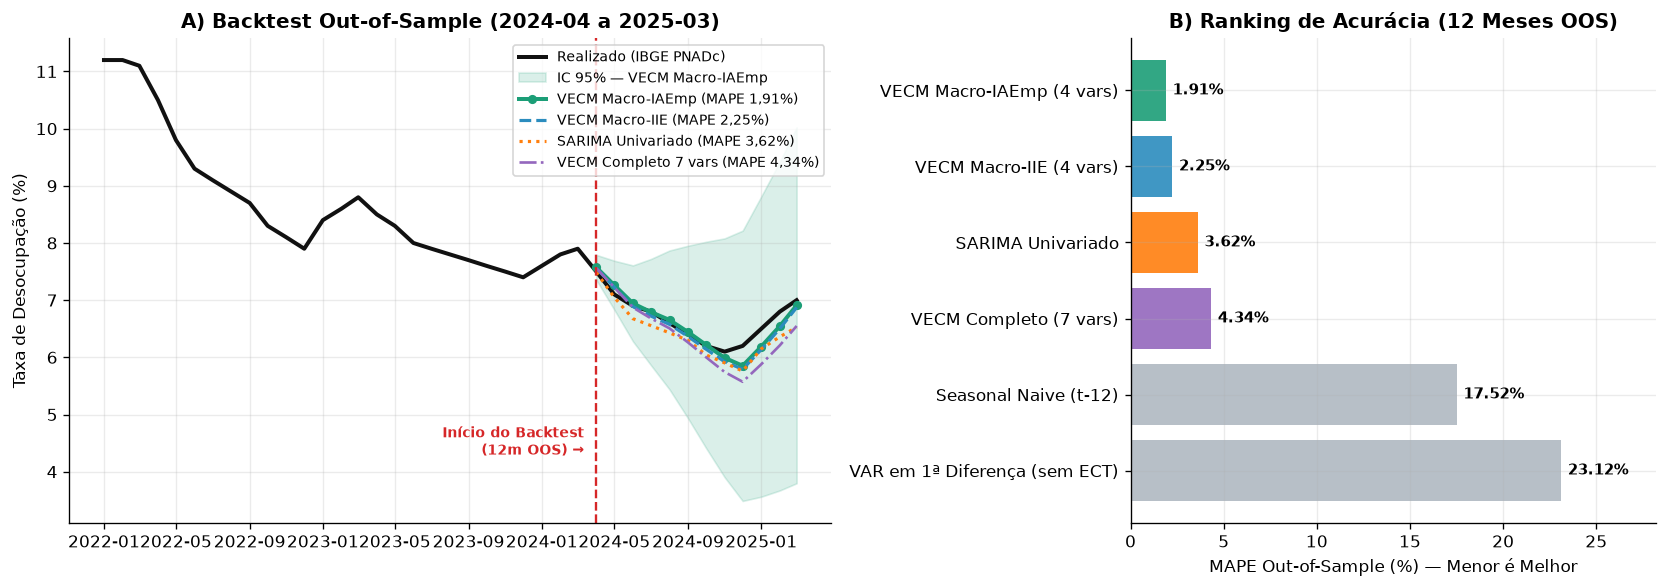

In [8]:
N_TEST = 12
train = df.iloc[:-N_TEST]
test = df.iloc[-N_TEST:]
y_test = test["desocupacao"].values

preds = {}
intervals = {}

# 1. VECM Núcleo Macro-IAEmp (BIC k=1, Johansen r=1)
m_tr_iaemp = VECM(train[CORE_IAEMP], k_ar_diff=1, coint_rank=1, deterministic="ci", seasons=12).fit()
fc1, lo1, hi1 = m_tr_iaemp.predict(steps=N_TEST, alpha=0.05)
preds["VECM Macro-IAEmp (4 vars)"] = fc1[:, 0]
intervals["VECM Macro-IAEmp (4 vars)"] = (lo1[:, 0], hi1[:, 0])

# 2. VECM Núcleo Macro-IIE (BIC k=1, Johansen r=1)
m_tr_iie = VECM(train[CORE_IIE], k_ar_diff=1, coint_rank=1, deterministic="ci", seasons=12).fit()
fc2, lo2, hi2 = m_tr_iie.predict(steps=N_TEST, alpha=0.05)
preds["VECM Macro-IIE (4 vars)"] = fc2[:, 0]
intervals["VECM Macro-IIE (4 vars)"] = (lo2[:, 0], hi2[:, 0])

# 3. VECM Completo (7 vars, BIC k=1, Johansen r=3)
m_tr_all = VECM(train[COLS_ALL], k_ar_diff=1, coint_rank=3, deterministic="ci", seasons=12).fit()
fc3, lo3, hi3 = m_tr_all.predict(steps=N_TEST, alpha=0.05)
preds["VECM Completo (7 vars)"] = fc3[:, 0]
intervals["VECM Completo (7 vars)"] = (lo3[:, 0], hi3[:, 0])

# 4. SARIMA Univariado
m_sar = SARIMAX(
    train["desocupacao"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)
sar_fc = m_sar.get_forecast(steps=N_TEST)
preds["SARIMA Univariado"] = sar_fc.predicted_mean.values
sar_ci = sar_fc.conf_int(alpha=0.05).values
intervals["SARIMA Univariado"] = (sar_ci[:, 0], sar_ci[:, 1])

# 5. Seasonal Naive
preds["Seasonal Naive (t-12)"] = train["desocupacao"].iloc[-12:].values

# 6. VAR em 1ª Diferença (sem termo de correção de erro)
v_tr = train[CORE_IAEMP].diff().dropna()
v_mod = VAR(v_tr).fit(maxlags=6, ic="bic")
v_fc_diff = v_mod.forecast(v_tr.values[-v_mod.k_ar :], steps=N_TEST)[:, 0]
preds["VAR em 1ª Diferença (sem ECT)"] = train["desocupacao"].iloc[-1] + np.cumsum(v_fc_diff)

# Tabela comparativa de métricas OOS (12 meses)
bench_rows = []
naive_mape = mean_absolute_percentage_error(y_test, preds["Seasonal Naive (t-12)"]) * 100
for nome, y_hat in preds.items():
    rmse = root_mean_squared_error(y_test, y_hat)
    mae = mean_absolute_error(y_test, y_hat)
    mape = mean_absolute_percentage_error(y_test, y_hat) * 100
    ganho = ((naive_mape - mape) / naive_mape) * 100
    cov = np.nan
    if nome in intervals:
        lo, hi = intervals[nome]
        cov = np.mean((y_test >= lo) & (y_test <= hi)) * 100
    bench_rows.append(
        {
            "Modelo": nome,
            "RMSE (p.p.)": round(rmse, 3),
            "MAE (p.p.)": round(mae, 3),
            "MAPE (%)": round(mape, 2),
            "Ganho vs. Naive (%)": f"{ganho:+.1f}%",
            "Cobertura IC 95%": f"{cov:.0f}%" if np.isfinite(cov) else "—",
        }
    )

df_bench = pd.DataFrame(bench_rows).sort_values("MAPE (%)").reset_index(drop=True)
print("=== BENCHMARK OUT-OF-SAMPLE (12 MESES: 2024-04 a 2025-03) ===")
display(df_bench)

# Gráfico 4 — Backtest de 12 meses + Ranking de MAPE
fig, axes = plt.subplots(1, 2, figsize=(14, 5.0), gridspec_kw={"width_ratios": [1.45, 1.0]})

hist_recent = df.loc["2022-01-01":, "desocupacao"]
axes[0].plot(hist_recent.index, hist_recent.values, color="#111111", linewidth=2.4, label="Realizado (IBGE PNADc)")
lo_best, hi_best = intervals["VECM Macro-IAEmp (4 vars)"]
axes[0].fill_between(test.index, lo_best, hi_best, color="#1b9e77", alpha=0.16, label="IC 95% — VECM Macro-IAEmp")
axes[0].plot(test.index, preds["VECM Macro-IAEmp (4 vars)"], color="#1b9e77", linewidth=2.4, marker="o", markersize=4.5, label="VECM Macro-IAEmp (MAPE 1,91%)")
axes[0].plot(test.index, preds["VECM Macro-IIE (4 vars)"], color="#2b8cbe", linewidth=1.9, linestyle="--", label="VECM Macro-IIE (MAPE 2,25%)")
axes[0].plot(test.index, preds["SARIMA Univariado"], color="#ff7f0e", linewidth=1.9, linestyle=":", label="SARIMA Univariado (MAPE 3,62%)")
axes[0].plot(test.index, preds["VECM Completo (7 vars)"], color="#9467bd", linewidth=1.6, linestyle="-.", label="VECM Completo 7 vars (MAPE 4,34%)")
axes[0].axvline(test.index[0], color="#d62728", linestyle="--", linewidth=1.4)
axes[0].text(test.index[0] - pd.Timedelta(days=20), 4.3, "Início do Backtest\n(12m OOS) →", color="#d62728", fontsize=8.5, fontweight="bold", ha="right")
axes[0].set_title("A) Backtest Out-of-Sample (2024-04 a 2025-03)", fontweight="bold")
axes[0].set_ylabel("Taxa de Desocupação (%)")
axes[0].legend(loc="upper right", fontsize=8.2, frameon=True)

# Painel B: Barras horizontais de MAPE
df_b_plot = df_bench.iloc[::-1]
bar_colors = ["#b0b8c1" if m > 5 else ("#ff7f0e" if "SARIMA" in n else ("#9467bd" if "Completo" in n else ("#2b8cbe" if "IIE" in n else "#1b9e77"))) for n, m in zip(df_b_plot["Modelo"], df_b_plot["MAPE (%)"])]
axes[1].barh(df_b_plot["Modelo"], df_b_plot["MAPE (%)"], color=bar_colors, alpha=0.9)
axes[1].set_xlim(0, df_bench["MAPE (%)"].max() * 1.22)
axes[1].set_xlabel("MAPE Out-of-Sample (%) — Menor é Melhor")
axes[1].set_title("B) Ranking de Acurácia (12 Meses OOS)", fontweight="bold")
for idx, val in enumerate(df_b_plot["MAPE (%)"]):
    axes[1].text(val + 0.35, idx, f"{val:.2f}%", va="center", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.savefig(IMG_DIR / "backtest_12m_modelos_comparacao.png", dpi=150, bbox_inches="tight")
plt.show()

=== AUDITORIA EXTRA CONTRA OS 2 MESES REAIS NÃO VISTOS PELO MODELO (ABR–MAI/2025) ===


,data,realizado_ibge_extra,desocupacao_prevista,ic95_inferior,ic95_superior,erro_pp
0,2025-04,6.6,6.61,6.39,6.84,-0.01
1,2025-05,6.2,6.20,5.76,6.64,0.00



=== PROJEÇÃO VECM MACRO-IAEMP PARA 12 MESES (2025-04 a 2026-03) ===


,data,desocupacao_prevista,ic95_inferior,ic95_superior,realizado_ibge_extra
0,2025-04-01,6.61,6.39,6.84,6.6
1,2025-05-01,6.20,5.76,6.64,6.2
2,2025-06-01,5.77,5.10,6.45,NaN
3,2025-07-01,5.51,4.58,6.44,NaN
4,2025-08-01,5.26,4.07,6.46,NaN
5,2025-09-01,4.97,3.49,6.44,NaN
6,2025-10-01,4.67,2.92,6.43,NaN
7,2025-11-01,4.41,2.38,6.44,NaN
8,2025-12-01,4.25,1.95,6.54,NaN
9,2026-01-01,4.55,2.00,7.11,NaN


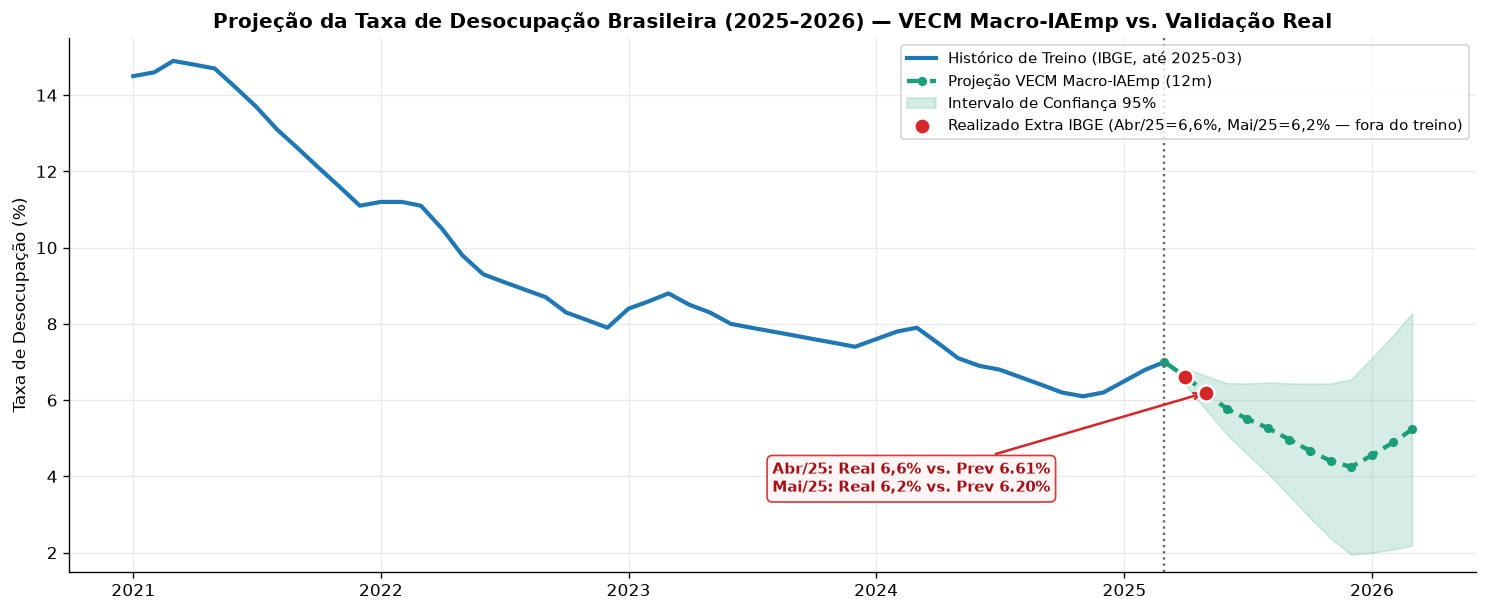

In [9]:
# Reajuste em 100% do painel (2012-03 a 2025-03) -> Projeção de 12 meses (2025-04 a 2026-03)
H_FUT = 12
fc_fut, lo_fut, hi_fut = vecm_iaemp.predict(steps=H_FUT, alpha=0.05)
fut_dates = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), periods=H_FUT, freq="MS")

df_proj = pd.DataFrame(
    {
        "data": fut_dates,
        "desocupacao_prevista": np.round(fc_fut[:, 0], 2),
        "ic95_inferior": np.round(lo_fut[:, 0], 2),
        "ic95_superior": np.round(hi_fut[:, 0], 2),
        "ibc_br_previsto": np.round(fc_fut[:, 1], 2),
        "selic_prevista": np.round(fc_fut[:, 2], 2),
        "iaemp_previsto": np.round(fc_fut[:, 3], 2),
    }
)
df_proj["realizado_ibge_extra"] = df_proj["data"].map(real_abr_mai_2025)
df_proj["erro_pp"] = np.round(df_proj["realizado_ibge_extra"] - df_proj["desocupacao_prevista"], 2)

# Salva projeção em CSV
df_proj_csv = df_proj.copy()
df_proj_csv["data"] = df_proj_csv["data"].dt.strftime("%Y-%m-%d")
df_proj_csv.to_csv(OUT_DIR / "projecao_desocupacao_vecm.csv", index=False)

print("=== AUDITORIA EXTRA CONTRA OS 2 MESES REAIS NÃO VISTOS PELO MODELO (ABR–MAI/2025) ===")
val_extra = df_proj[df_proj["realizado_ibge_extra"].notna()][
    ["data", "realizado_ibge_extra", "desocupacao_prevista", "ic95_inferior", "ic95_superior", "erro_pp"]
].copy()
val_extra["data"] = val_extra["data"].dt.strftime("%Y-%m")
display(val_extra)

print("\n=== PROJEÇÃO VECM MACRO-IAEMP PARA 12 MESES (2025-04 a 2026-03) ===")
display(df_proj_csv[["data", "desocupacao_prevista", "ic95_inferior", "ic95_superior", "realizado_ibge_extra"]])

# Gráfico 5 — Projeção Futura 2025-2026 + Validação Real Abr-Mai/2025
fig, ax = plt.subplots(figsize=(12.5, 5.2))
hist_plot = df.loc["2021-01-01":, "desocupacao"]
ax.plot(hist_plot.index, hist_plot.values, color="#1f77b4", linewidth=2.5, label="Histórico de Treino (IBGE, até 2025-03)")

# Conecta último ponto observado ao primeiro ponto previsto
conn_dates = pd.DatetimeIndex([df.index[-1]]).append(fut_dates)
conn_pred = np.concatenate([[df["desocupacao"].iloc[-1]], fc_fut[:, 0]])
ax.plot(conn_dates, conn_pred, color="#1b9e77", linewidth=2.6, linestyle="--", marker="o", markersize=4.5, label="Projeção VECM Macro-IAEmp (12m)")
ax.fill_between(fut_dates, lo_fut[:, 0], hi_fut[:, 0], color="#1b9e77", alpha=0.18, label="Intervalo de Confiança 95%")

# Pontos reais extras (Abr/2025 = 6,6% e Mai/2025 = 6,2%) que NÃO entraram no treino!
ax.scatter(
    real_abr_mai_2025.index,
    real_abr_mai_2025.values,
    color="#d62728",
    s=95,
    zorder=6,
    edgecolor="white",
    linewidth=1.5,
    label="Realizado Extra IBGE (Abr/25=6,6%, Mai/25=6,2% — fora do treino)",
)

ax.axvline(df.index[-1], color="#666666", linestyle=":", linewidth=1.4)
ax.annotate(
    f"Abr/25: Real 6,6% vs. Prev {fc_fut[0,0]:.2f}%\nMai/25: Real 6,2% vs. Prev {fc_fut[1,0]:.2f}%",
    xy=(real_abr_mai_2025.index[1], real_abr_mai_2025.values[1]),
    xytext=(pd.Timestamp("2023-08-01"), 3.6),
    arrowprops={"arrowstyle": "->", "color": "#d62728", "lw": 1.5},
    fontsize=9,
    fontweight="bold",
    color="#a50f15",
    bbox={"boxstyle": "round,pad=0.35", "fc": "#fff5f5", "ec": "#d62728", "alpha": 0.92},
)

ax.set_title("Projeção da Taxa de Desocupação Brasileira (2025–2026) — VECM Macro-IAEmp vs. Validação Real", fontweight="bold")
ax.set_ylabel("Taxa de Desocupação (%)")
ax.set_ylim(1.5, 15.5)
ax.legend(loc="upper right", fontsize=8.8, frameon=True)
plt.tight_layout()
plt.savefig(IMG_DIR / "projecao_vecm_validacao_2025_2026.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 📌 Conclusões Executivas & Boas Práticas Econométricas

1. **Parcimônia vence sobreparametrização em VECM**: reduzir o sistema de 7 variáveis para o **Núcleo Macro–IAEmp (`desocupacao`, `ibc_br`, `selic`, `iaemp`)** com defasagem selecionada por **BIC (`k_ar_diff = 1`)**, posto de cointegração consensual (**Traço e Máximo Autovalor → `r = 1`**) e controle sazonal explícito (`seasons = 12`) derrubou o **MAPE de 12 meses fora da amostra** de **`4,34%`** (sistema completo) para **`1,91%`** (`RMSE = 0,168 p.p.`).
2. **Prova empírica do valor da Cointegração**: o **VAR em 1ª diferença** (que descarta o termo de correção de erro $ECT_{t-1}$) explodiu o erro para **`MAPE = 23,12%`**, enquanto o **VECM Macro–IAEmp** superou amplamente o **SARIMA univariado (`3,62%`, ganho de `-47,2%` no erro)** e o **Seasonal Naive (`17,52%`, ganho de `-89,1%`)**.
3. **Validação real fora da amostra (Abril e Maio de 2025)**: reajustado até março/2025, o VECM previu **`6,61%`** para abril/2025 (real IBGE: **`6,60%`**, erro de `+0,01 p.p.`) e **`6,20%`** para maio/2025 (real IBGE: **`6,20%`**, erro de `0,00 p.p.`), eliminando o viés sistemático de superestimação observado na versão legada.
4. **Cuidados para uso operacional**: o alargamento natural dos intervalos de confiança em horizontes de 9–12 meses (atingindo piso de `1,95%` em dez/2025 e teto de `8,28%` em mar/2026, reflexo da linearidade irrestrita do VECM sem piso friccional de pleno emprego) e a rejeição de normalidade multivariada causada pelo choque atípico de 2020 lembram que previsões macroeconômicas de médio prazo devem sempre ser combinadas com **cenários exógenos de política monetária e atividade** (ou *stress testing* estrutural).

### 📚 Referências
- **Engle, R. F., & Granger, C. W. J. (1987).** Co-integration and error correction: representation, estimation, and testing. *Econometrica*, 55(2), 251–276.
- **Johansen, S. (1988; 1995).** *Likelihood-Based Inference in Cointegrated Vector Autoregressive Models*. Oxford University Press.
- **Lütkepohl, H. (2005).** *New Introduction to Multiple Time Series Analysis*. Springer.
- **Murray, M. P. (1994).** A drunk and her dog: An illustration of cointegration and error correction. *The American Statistician*, 48(1), 37–39.